# Q1E | Train Polynomial Regression

> E. Repeat everything from part D with polynomial regression and using SGD. Using validation loss, explore if your model overfits/underfits the data and report your findings. Ensure reproducibility by using a seed.

Part D, which this repeats:

> Train a Linear Regression model using the training data with four-fold cross-validation and with appropriate evaluation metric. Do this with a closed-form solution (using the Normal Equation or SVD) and with SGD. Then focus on SGD and perform Ridge, Lasso and Elastic Net regularization – try three values of penalty term and describe its impact. Explore the impact of other hyperparameters of your choice, such as learning rate (no need for grid search). Describe your findings. Select the best-performing regularization set of hyperparameters and train that model on the entire training dataset. For SGD, display the training and validation loss as a function of training epochs for the selected model. (Hint: In scikit-learn, max_iter counts epochs (full passes over the training set). To plot training/validation loss by epoch with SGDRegressor, set max_iter=1 and warm_start=True, then call fit(...) in a loop; after each call (each epoch), compute and record Train and Validation RMSE). Ensure reproducibility by using a seed.

**IMPORTANT**

This notebook uses only the train dataset, so no modeling decision is influenced by the test data (data snooping). Every score below is a cross validation score on the training rows.

# Answer Summary

**Cross validation and metric**
- Four-fold cross validation (`KFold`, shuffled with seed 42), scored by RMSE in `Life Ladder` points. Validation rows are complete rows only, like the test file.
- Each choice starts from the simpler option, which another replaces only if its mean validation RMSE is at least 1% lower.

**Polynomial regression: degree**
- Every attribute's columns are expanded. By closed form (SVD), degree 2 is kept: 0.4980 against 0.5178 at degree 1, and degree 3 is 19.32% worse.

**Missing values**
- Dropping the 185 incomplete rows is kept: all 8 imputers are worse, the closest (KNN + missing flags) by 0.18%. Every model trains on the 1,374 complete rows.

**Closed form vs SGD**
- SGD at scikit-learn's defaults lands just above the closed form: 0.4987 against 0.4980.

**Other hyperparameters**
- `eta0`: only a narrow range works; 0.1 diverges, 0.001 is 2.08% worse, and the default 0.01 is kept.
- Schedule: only the default `invscaling` survives at a step of 0.01; the other three diverge on the expanded columns.

**Regularization**
- A weak penalty changes nothing: at alpha 0.001 every penalty is within 0.0006 of no penalty.
- L1 bites first: at alpha 0.1 Lasso rises to 0.5380 while Ridge stays near no penalty.
- A strong penalty underfits: at alpha 10 Lasso and Elastic Net predict the mean.

**Selected model**
- Elastic Net at alpha 0.001 (`invscaling`, `eta0` 0.01, degree 2), picked as required: 0.4981 against 0.4987 without a penalty.
- Trained on the 1,374 complete rows and saved: training RMSE 0.4855.

**Loss by epoch**
- Most of the learning happens in the first 2 epochs; validation RMSE then edges down to 0.4981 and never turns up.
- The homework's loop restarts the step at 0.01 every epoch, so it flattens early and ends higher (0.5016).

**Overfitting and underfitting**
- Degree 1 underfits; from degree 3 the closed form overfits (training RMSE falls to 0.4083 while validation RMSE rises to 0.5942).
- The selected model fits well: a small gap between training and validation RMSE (0.4848 against 0.4981), no overfitting for a penalty to cure, and none from more epochs.

**Reproducibility**
- Seed 42 for the fold shuffle and every SGD model.

---

# Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyRegressor
from sklearn.experimental import enable_iterative_imputer  # makes IterativeImputer importable
from sklearn.impute import IterativeImputer, MissingIndicator, SimpleImputer
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import make_union

import Q1.consts as Q1_CONSTS
from Q1.utils import ScaledKNNImputer
from consts import SEED, CARRY_MARGIN, CV_SPLITS, MAX_ITER, TOL, POWER_T, LEARNING_RATE_SCHEDULES, ETA0S, ALPHAS, L1_RATIO, DEGREES

from utils import (
	read_csv_to_df,
	STATISTICS,
	PLOTTING,
	PIPELINES,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)  # a diverging run would otherwise switch a whole table to 1e+12 style

# Fetch Data

In [2]:
train_df = read_csv_to_df(path=Q1_CONSTS.TRAIN_PATH)

ATTRIBUTES = [column for column in train_df.columns if column != Q1_CONSTS.TARGET]
X, y = train_df[ATTRIBUTES], train_df[Q1_CONSTS.TARGET]

# Setup

## Folds

In [3]:
# Validation rows are complete rows only, as in the test file. The incomplete rows are added to the training side of
# every fold, so a model that imputes them and one that drops them are scored on the same validation rows.
complete = np.flatnonzero(X.notna().all(axis=1))
incomplete = np.flatnonzero(X.isna().any(axis=1))
cuts = KFold(n_splits=CV_SPLITS, shuffle=True, random_state=SEED).split(complete)
FOLDS = [(np.concatenate([complete[train], incomplete]), complete[validation]) for train, validation in cuts]
DROP_FOLDS = [(train[np.isin(train, complete)], validation) for train, validation in FOLDS]  # the same folds without the incomplete rows

pd.DataFrame({
	'folds': [len(FOLDS), len(DROP_FOLDS)],
	'training rows': [f'{min(len(t) for t, _ in folds)} to {max(len(t) for t, _ in folds)}' for folds in (FOLDS, DROP_FOLDS)],
	'validation rows': [f'{min(len(v) for _, v in folds)} to {max(len(v) for _, v in folds)}' for folds in (FOLDS, DROP_FOLDS)],
}, index=['FOLDS (incomplete rows imputed)', 'DROP_FOLDS (incomplete rows dropped)'])

,folds,training rows,validation rows
FOLDS (incomplete rows imputed),4,1215 to 1216,343 to 344
DROP_FOLDS (incomplete rows dropped),4,1030 to 1031,343 to 344


## Features

| Attribute | Shape | Source |
|---|---|---|
| `Log GDP per capita` | raw | Q1B; its hinge only tied raw in earlier experiments |
| `Social support` | reciprocal, 1 / (1.2 - x) (`'reciprocal'`) | Q1B |
| `Healthy life expectancy at birth` | floor at 56.8 (`'floor'`) | Q1B; Q1C found r 0.851 with `Log GDP per capita`, but dropping it cost more than any other attribute in earlier experiments |
| `Freedom to make life choices` | raw | Q1B suggested a hinge at 0.8; raw tied it in earlier experiments |
| `Generosity` | hinge at 0.305 (`'hinge'`) | Q1B's second shape; it beat Q1B's flag in earlier experiments |
| `Perceptions of corruption` | raw | Q1B found no shape |
| `Positive affect` | raw | Q1B found no shape |
| `Negative affect` | dropped | dropping it beat keeping it in earlier experiments |

In [4]:
GDP, SOCIAL, LIFE_EXP, FREEDOM, GENEROSITY, CORRUPTION, POS_AFFECT, NEG_AFFECT = ATTRIBUTES
FITS = {attribute: STATISTICS.shape_fits(df=train_df, feature=attribute, target=Q1_CONSTS.TARGET) for attribute in ATTRIBUTES}

def shape(*, attribute, name):
	"""Q1B's shape of an attribute by name (ex 'hinge'), with the setting Q1B found, as a pipeline step."""
	return next(fit for fit in FITS[attribute] if fit.name == name).transformer

SHAPES = {
	GDP: 'passthrough',  # Q1B; its hinge only tied raw in earlier experiments
	SOCIAL: shape(attribute=SOCIAL, name='reciprocal'),  # Q1B
	LIFE_EXP: shape(attribute=LIFE_EXP, name='floor'),  # Q1B; Q1C found r 0.851 with `Log GDP per capita`, but dropping it cost more than any other attribute in earlier experiments
	FREEDOM: 'passthrough',  # Q1B suggested a hinge at 0.8; raw tied it in earlier experiments
	GENEROSITY: shape(attribute=GENEROSITY, name='hinge'),  # Q1B's second shape; it beat Q1B's flag in earlier experiments
	CORRUPTION: 'passthrough',  # Q1B found no shape
	POS_AFFECT: 'passthrough',  # Q1B found no shape
	NEG_AFFECT: 'drop',  # dropping it beat keeping it in earlier experiments
}

## Runs

In [5]:
RUNS = {}  # every cross validation result, keyed by name

def build(*, model, imputer=None, degree=1):
	"""The pipeline of one experiment on the features: imputer (none by default: the incomplete rows are dropped),
	shapes, standardized columns, polynomial terms above degree 1, model (see PIPELINES.build_pipeline)."""
	return PIPELINES.build_pipeline(model=model, attributes=ATTRIBUTES, shapes=SHAPES, imputer=imputer, degree=degree)

def score(*, name, pipeline, folds=DROP_FOLDS):
	"""Cross validate a pipeline and keep its result under name. The default folds leave the incomplete rows out, to go
	with build's default."""
	RUNS[name] = PIPELINES.cv_rmse(pipeline=pipeline, X=X, y=y, folds=folds)

def table(*, names, baseline=None):
	"""One row per run in names: mean validation RMSE, mean training RMSE, the most epochs for SGD, and the change from
	the baseline when one is given."""
	return STATISTICS.results_df(runs={name: RUNS[name] for name in names}, baseline=baseline)

def lowest(*, names):
	"""The run in names with the lowest mean validation RMSE."""
	return min(names, key=lambda name: RUNS[name]['validation rmse'].mean())

def carried(*, baseline, names):
	"""The decision rule: the run in names with the lowest mean validation RMSE replaces the baseline (the simpler
	option) only if it is at least CARRY_MARGIN (1%) lower; otherwise the baseline is kept."""
	best = lowest(names=names)
	gain = 1 - RUNS[best]['validation rmse'].mean() / RUNS[baseline]['validation rmse'].mean()
	return best if gain >= CARRY_MARGIN else baseline

# Method

- **Metric:** RMSE in `Life Ladder` points. `validation rmse` is the mean over the 4 folds of the RMSE on each fold's validation rows, rows the model never saw; every choice is made on it. `train rmse` is the same on the rows each model was fit on: far below `validation rmse` means the model fits its own rows better than new ones.
- **Folds:** four-fold cross validation (`KFold`), shuffled with seed 42. Validation rows are the 1,374 complete rows only, like the test file, which Q1A found has no missing values. The 185 incomplete rows sit on the training side when an imputer fills them and are left out when they are dropped, so every option is scored on the same validation rows.
- **Rule:** each choice starts from a baseline, the simpler option: degree 2, dropping the incomplete rows, and scikit-learn's default `eta0` (0.01) and schedule (`invscaling`). The option with the lowest mean validation RMSE replaces the baseline only if it is at least 1% lower (`CARRY_MARGIN`); a smaller gain is not worth the added step. The `% vs baseline` column shows the change. The selected regularized model has no baseline: the lowest mean wins. Degree 1 is D's model, not polynomial regression: it is shown for reference but cannot be carried.
- **Pipeline:** imputer (only when one is carried), shapes, every attribute's columns standardized (the missing flags stay 0/1), polynomial terms, model. The target is standardized too, so `alpha` and `tol` mean the same thing in Q1 and Q2 (Q1D's Why the Target Is Standardized shows what this changes), and the predictions come back in `Life Ladder` points. Every step is fit on the training rows of a fold only.
- **Polynomial terms:** at degree d, the standardized columns are expanded into every product of up to d of them (`PolynomialFeatures` without a column of 1s, since the model fits its own intercept), then standardized again. Every attribute's columns are expanded; the missing flags are not.
- **Closed form:** least squares solved by SVD (`PIPELINES.SVDRegression`, numpy's `lstsq`). Some expanded columns are exact combinations of others: `LinearRegression` returns huge coefficients on them, while SVD returns the solution with the smallest coefficients.
- **Seed:** seed 42 for every step that has randomness: the fold shuffle, the iterative imputer and every SGD model. Dummy, SVD, mean, median and KNN are deterministic.
- **Optimism:** every choice is made on these folds and Q1B's shape settings were found on all training rows, so the scores are a little optimistic; the test set gives the honest estimate.

# Baselines

Dummy predicts the training mean of each fold, with the incomplete rows dropped (the baseline for missing values).

In [6]:
score(name='Dummy', pipeline=build(model=DummyRegressor()))
YMAX = 1.1 * RUNS['Dummy']['validation rmse'].mean()  # a run that diverges is drawn at the top of a chart instead of flattening the rest

table(names=['Dummy'])

,validation rmse,train rmse
Dummy,1.1281,1.1279


### Notes / Observations

- **The reference every degree is read against:** predicting the training mean scores 1.1281.

# Degree

The closed form on the features at degrees 1 to 4, with the incomplete rows dropped. Degree 2 is the baseline (rule in Method); degree 1 is D's model, shown for reference only. Training and validation RMSE side by side show underfitting (both high and close) and overfitting (training RMSE falling while validation RMSE rises).

,validation rmse,train rmse,% vs baseline
Dummy,1.1281,1.1279,+126.52%
"Closed form, degree 1",0.5178,0.5132,+3.97%
"Closed form, degree 2",0.4980,0.4811,baseline
"Closed form, degree 3",0.5942,0.4083,+19.32%
"Closed form, degree 4",3.3463,0.3293,+571.92%


,carried
degree,2


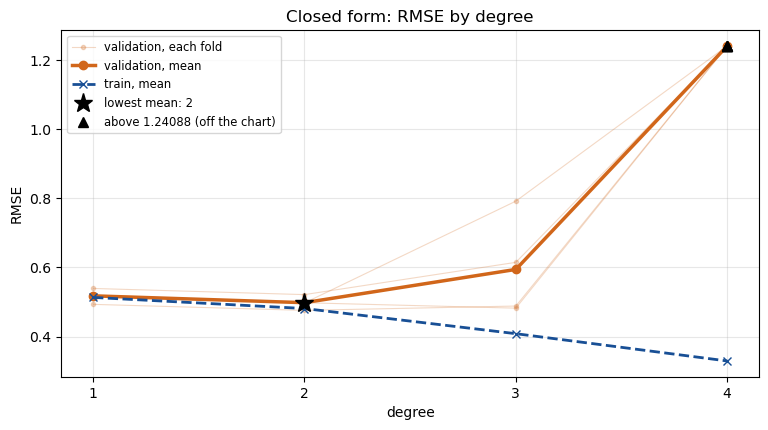

In [7]:
names = {degree: f'Closed form, degree {degree}' for degree in DEGREES}
for degree, name in names.items():
	score(name=name, pipeline=build(model=PIPELINES.SVDRegression(), degree=degree))

display(table(names=['Dummy', *names.values()], baseline=names[2]))
PLOTTING.parameter_search(runs={degree: RUNS[name] for degree, name in names.items()}, parameter='degree', ymax=YMAX, title='Closed form: RMSE by degree')

POLYNOMIAL = [names[degree] for degree in DEGREES if degree > 1]  # degree 1 is not polynomial regression
DEGREE = next(degree for degree, name in names.items() if name == carried(baseline=names[2], names=POLYNOMIAL))
pd.Series({'degree': DEGREE}, name='carried').to_frame()

### Notes / Observations

- **Degree 2 is kept:** it is the baseline, and degrees 3 and 4 are both worse (degree 3: +19.32%).
- **Degree 1 underfits:** degree 2's squares and products lower training and validation RMSE together (validation: 0.5178 to 0.4980).
- **From degree 3 the closed form overfits:** training RMSE keeps falling (0.4083 at degree 3) while validation RMSE rises, up to 3.3463 at degree 4.

# Missing Values

Ways to handle the 185 incomplete training rows, all by closed form on the features at the carried degree:
- **Drop incomplete rows (baseline):** train on the 1,374 complete rows only. The simpler option: no imputer.
- **Mean:** fill with the attribute's training mean.
- **Median:** fill with the attribute's training median, which skewed values pull less than the mean.
- **KNN:** fill with the mean of the 5 most similar rows, measured on standardized attributes and returned in the attributes' own units (`ScaledKNNImputer`; the shapes need those units).
- **Iterative:** predict each missing value from the other attributes, in rounds (`IterativeImputer`).
- **+ missing flags:** each fill again, plus a 0/1 column per kept attribute with missing values, marking the filled rows. The flags enter the model as 0/1: not standardized or expanded.

The imputer with the lowest mean replaces dropping only if it is at least 1% lower (Method). If dropping is kept, every later model trains on the complete rows only.

In [8]:
KEPT = [attribute for attribute in ATTRIBUTES if SHAPES[attribute] != 'drop']  # the attributes the model keeps

def with_flags(*, imputer):
	"""The imputer, plus a 0/1 column per kept attribute with missing values, marking the filled rows."""
	return make_union(imputer, make_column_transformer((MissingIndicator(), KEPT)))  # the filled attributes come first, so the shapes find them by position

IMPUTERS = {'Drop incomplete rows': None}
for name, imputer in {
	'Mean': SimpleImputer(strategy='mean'),
	'Median': SimpleImputer(strategy='median'),
	'KNN': ScaledKNNImputer(),
	'Iterative': IterativeImputer(random_state=SEED),
}.items():
	IMPUTERS[name] = imputer
	IMPUTERS[f'{name} + missing flags'] = with_flags(imputer=imputer)
for name, imputer in IMPUTERS.items():
	score(name=name, pipeline=build(model=PIPELINES.SVDRegression(), imputer=imputer, degree=DEGREE), folds=DROP_FOLDS if imputer is None else FOLDS)

display(table(names=list(IMPUTERS), baseline='Drop incomplete rows'))
CLOSED_FORM = carried(baseline='Drop incomplete rows', names=IMPUTERS)  # the carried closed form, the one SGD is compared against
IMPUTER = IMPUTERS[CLOSED_FORM]
CV_FOLDS = DROP_FOLDS if IMPUTER is None else FOLDS
print(f'carried: {CLOSED_FORM}')

,validation rmse,train rmse,% vs baseline
Drop incomplete rows,0.4980,0.4811,baseline
Mean,0.5020,0.4902,+0.79%
Mean + missing flags,0.5010,0.4856,+0.61%
Median,0.5027,0.4904,+0.93%
Median + missing flags,0.5013,0.4858,+0.66%
KNN,0.4993,0.4909,+0.25%
KNN + missing flags,0.4989,0.4871,+0.18%
Iterative,0.5000,0.4941,+0.41%
Iterative + missing flags,0.4994,0.4901,+0.28%


carried: Drop incomplete rows


### Notes / Observations

- **Dropping the incomplete rows is kept, and every imputer is worse:** the closest, KNN + missing flags, is 0.18% higher, so every later model trains on the 1,374 complete rows.
- **The simple fills cost the most:** mean and median are the worst (Median: +0.93%); KNN and iterative, which fill from the other attributes, come closer.
- **Missing flags help every fill a little** (Mean: +0.79% to +0.61%), but none catches up with dropping.
- **The saved model will have no imputer:** it can only predict complete rows. The test file is complete, so this does not affect F; a new row with a missing value would need an imputer.

# SGD

`SGDRegressor` on the features at the carried degree, starting from scikit-learn's defaults with every setting written out (`penalty=None`, since the default is a light L2 penalty). `max_iter` is a ceiling: a fit stops once its training loss improves by less than `tol` for 5 epochs in a row.

In [9]:
SGD_SETTINGS = dict(penalty=None, learning_rate='invscaling', eta0=0.01, power_t=POWER_T, max_iter=MAX_ITER, tol=TOL, random_state=SEED)  # scikit-learn's defaults, written out
SETTINGS = {}  # the settings of every SGD run, keyed by name

def sgd(*, name, settings):
	"""Cross validate SGD with these settings at the carried degree, imputer and folds, and keep the settings under name."""
	SETTINGS[name] = settings
	score(name=name, pipeline=build(model=SGDRegressor(**settings), imputer=IMPUTER, degree=DEGREE), folds=CV_FOLDS)

## SGD vs Closed Form

In [10]:
sgd(name='SGD', settings=SGD_SETTINGS)

table(names=[CLOSED_FORM, 'SGD'])

,validation rmse,train rmse,most epochs
Drop incomplete rows,0.4980,0.4811,<NA>
SGD,0.4987,0.4852,12


### Notes / Observations

- **At scikit-learn's defaults SGD lands just above the closed form:** 0.4987 against 0.4980, after at most 12 epochs.

## Learning Rate (eta0)

`eta0` is the starting step; under `invscaling` the step shrinks from it as training goes on. 5 values, with the schedule at its default. The default 0.01 is the baseline (rule in Method).

,validation rmse,train rmse,most epochs,% vs baseline
Drop incomplete rows,0.4980,0.4811,<NA>,-0.14%
eta0=1e-05,0.8886,0.8870,95,+78.18%
eta0=0.0001,0.5780,0.5737,48,+15.90%
eta0=0.001,0.5091,0.5000,14,+2.08%
eta0=0.01,0.4987,0.4852,12,baseline
eta0=0.1,321478990668.7302,315214781396.1406,6,> +999%


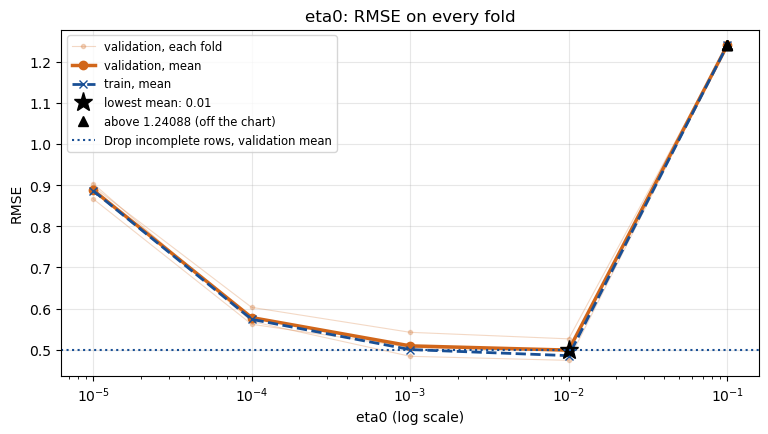

In [11]:
names = {eta0: f'eta0={eta0}' for eta0 in ETA0S}
for eta0, name in names.items():
	sgd(name=name, settings={**SGD_SETTINGS, 'eta0': eta0})
baseline = names[SGD_SETTINGS['eta0']]  # scikit-learn's default, 0.01

display(table(names=[CLOSED_FORM, *names.values()], baseline=baseline))
PLOTTING.parameter_search(
	runs={eta0: RUNS[name] for eta0, name in names.items()},
	parameter='eta0',
	log_x=True,
	reference=(CLOSED_FORM, RUNS[CLOSED_FORM]),
	ymax=YMAX,
	title='eta0: RMSE on every fold',
);

SGD_SETTINGS = SETTINGS[carried(baseline=baseline, names=names.values())]  # the settings with the carried eta0

### Notes / Observations

- **The default 0.01 is kept:** every other value is worse, and the closest, 0.001, is 2.08% higher.
- **Only a narrow range works:** 0.1 diverges, and 0.0001 and below stop well short (0.5780 at 0.0001).

## Learning Rate Schedule

At the carried `eta0`; `invscaling`, the default, is the baseline (rule in Method).
- `constant`: the step stays `eta0`.
- `optimal`: sets its own step from `alpha` and ignores `eta0`.
- `invscaling`: the step is `eta0 / t ** power_t`.
- `adaptive`: keeps `eta0` and divides it by 5 each time the training loss stalls for 5 epochs.

In [12]:
names = [f'learning_rate={schedule}' for schedule in LEARNING_RATE_SCHEDULES]
for schedule, name in zip(LEARNING_RATE_SCHEDULES, names):
	sgd(name=name, settings={**SGD_SETTINGS, 'learning_rate': schedule})
baseline = f"learning_rate={SGD_SETTINGS['learning_rate']}"  # scikit-learn's default, invscaling

display(table(names=[CLOSED_FORM, *names], baseline=baseline))
SGD_SETTINGS = SETTINGS[carried(baseline=baseline, names=names)]  # the settings with the carried schedule
display(pd.Series(SGD_SETTINGS, name='carried').astype(str).to_frame())  # as text: the float format would round a small eta0 to 0

,validation rmse,train rmse,most epochs,% vs baseline
Drop incomplete rows,0.4980,0.4811,<NA>,-0.14%
learning_rate=constant,284089267552.2576,275027239874.6206,6,> +999%
learning_rate=optimal,9098833065987.3594,7830482182406.5967,51,> +999%
learning_rate=invscaling,0.4987,0.4852,12,baseline
learning_rate=adaptive,19149267614.4211,15773357786.2440,36,> +999%


,carried
penalty,None
learning_rate,invscaling
eta0,0.01
power_t,0.25
max_iter,10000
tol,0.001
random_state,42


### Notes / Observations

- **Only `invscaling`, the default, survives at a step of 0.01:** `constant`, `optimal` and `adaptive` all diverge on the expanded columns.
- **The step has to shrink from the start:** `constant` and `adaptive` both begin with a step of 0.01 that does not shrink, and both diverge; `invscaling` shrinks it from the first update.

# Regularization

The carried SGD with a penalty: Ridge (`l2`), Lasso (`l1`) and Elastic Net (`elasticnet`, `l1_ratio` fixed at 0.5, an even mix of both). `alpha`, the penalty's strength, at 3 values a hundred times apart. Each is compared with the same SGD without a penalty.

,validation rmse,train rmse,most epochs
No penalty,0.4987,0.4852,12
"Ridge, alpha=0.001",0.4987,0.4852,12
"Ridge, alpha=0.1",0.5011,0.4904,12
"Ridge, alpha=10",0.8955,0.8958,12
"Lasso, alpha=0.001",0.4982,0.4853,12
"Lasso, alpha=0.1",0.5380,0.5352,8
"Lasso, alpha=10",1.1280,1.1279,6
"Elastic Net, alpha=0.001",0.4981,0.4848,12
"Elastic Net, alpha=0.1",0.5233,0.5188,8
"Elastic Net, alpha=10",1.1280,1.1279,6


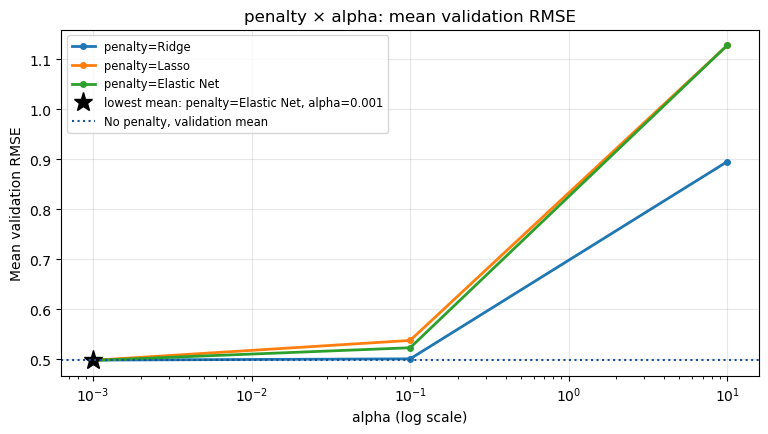

In [13]:
PENALTIES = {'Ridge': 'l2', 'Lasso': 'l1', 'Elastic Net': 'elasticnet'}
sgd(name='No penalty', settings=SGD_SETTINGS)

REGULARIZED = {(label, alpha): f'{label}, alpha={alpha}' for label in PENALTIES for alpha in ALPHAS}
for (label, alpha), name in REGULARIZED.items():
	sgd(name=name, settings={**SGD_SETTINGS, 'penalty': PENALTIES[label], 'alpha': alpha, **({'l1_ratio': L1_RATIO} if label == 'Elastic Net' else {})})

display(table(names=['No penalty', *REGULARIZED.values()]))
PLOTTING.parameter_cross(
	runs={pair: RUNS[name] for pair, name in REGULARIZED.items()},
	lines='penalty',
	x='alpha',
	log_x=True,
	reference=('No penalty', RUNS['No penalty']),
	ymax=YMAX,
);

### Notes / Observations

- **A weak penalty changes nothing:** at alpha 0.001 every penalty is within 0.0006 of no penalty (0.4987).
- **L1 bites first:** at alpha 0.1 Lasso rises to 0.5380 while Ridge stays near no penalty (0.5011); Elastic Net lands between them.
- **A strong penalty underfits:** at alpha 10 Ridge's training and validation RMSE rise together (0.8958 and 0.8955), and Lasso and Elastic Net predict the mean (1.1280).

# Selected Model

The homework asks for one regularized model, so the 9 regularized runs are ranked by mean validation RMSE and the lowest is selected. When no penalty improves on the model without one, the smallest alpha tends to win, because it changes the model the least: the selected model is then close to the model without a penalty, picked because the homework requires a regularized one, not because the penalty helps.

In [14]:
SELECTED = lowest(names=REGULARIZED.values())
display(pd.Series({**SETTINGS[SELECTED], 'degree': DEGREE}, name=SELECTED).astype(str).to_frame())  # as text: the float format would round a small alpha to 0

table(names=['No penalty', SELECTED])

,"Elastic Net, alpha=0.001"
penalty,elasticnet
learning_rate,invscaling
eta0,0.01
power_t,0.25
max_iter,10000
tol,0.001
random_state,42
alpha,0.001
l1_ratio,0.5
degree,2


,validation rmse,train rmse,most epochs
No penalty,0.4987,0.4852,12
"Elastic Net, alpha=0.001",0.4981,0.4848,12


### Notes / Observations

- **Elastic Net at alpha 0.001 is picked as required:** 0.4981 against 0.4987 without a penalty, the smallest alpha, as explained above.

## Train on the Entire Training Set

The selected model refit once, with no folds, on every training row kept (the 1,374 complete rows when dropping the incomplete rows is kept, all 1,559 rows when an imputer is carried) and saved. The saved pipeline takes the raw attributes and builds its own columns, at the carried degree. When dropping is kept, the saved pipeline has no imputer, so it can only predict complete rows.

In [15]:
X_full, y_full = (X.iloc[complete], y.iloc[complete]) if IMPUTER is None else (X, y)  # the complete rows only when dropping won
final = build(model=SGDRegressor(**SETTINGS[SELECTED]), imputer=IMPUTER, degree=DEGREE).fit(X_full, y_full)
Q1_CONSTS.MODEL_OUTPUT_DIR.mkdir(exist_ok=True)
joblib.dump(final, Q1_CONSTS.MODEL_OUTPUT_DIR / 'polynomial_regression.joblib')

pd.Series({
	'training rows': len(X_full),
	'epochs run': PIPELINES.final_model(pipeline=final).n_iter_,
	'train rmse': mean_squared_error(y_full, final.predict(X_full), squared=False),
}, dtype=object).to_frame(SELECTED)  # object: keeps the counts whole numbers

,"Elastic Net, alpha=0.001"
training rows,1374
epochs run,10
train rmse,0.4855


### Notes / Observations

- **The full fit matches the folds:** on the 1,374 complete rows its training RMSE is 0.4855, against 0.4848 averaged over the folds.

## Training and Validation Loss by Epoch

**What the chart is for:** following training and validation RMSE epoch by epoch, to see when training settles and whether more epochs start to overfit (validation RMSE turning up while training RMSE keeps falling). Each chart shows the selected model on every fold, for as many epochs as it ran on its longest fold.

**Two ways to draw it:**
- **The homework's loop:** a copy of the selected model with `max_iter=1` and `warm_start=True`, fit once per epoch on each fold's training rows, recording training and validation RMSE after each `fit` call.
- **The exact curve:** epoch k is a fresh fit of the selected model with `max_iter=k` and the same seed, which is exactly the first k epochs of its real training. A fold's line goes flat once `tol` stops it.

**Why they differ:** `warm_start=True` carries only the coefficients from one `fit` call to the next. Everything else starts over:

| | One long fit (how the selected model trained) | The homework's loop (one `fit` call per epoch) |
|---|---|---|
| Coefficients | carry on | carry on (`warm_start=True`) |
| Step under `constant` | `eta0` | `eta0`, the same |
| Step under `invscaling` (`eta0 / t ** power_t`, `t` counts the rows seen) | keeps shrinking | starts again at `eta0` every epoch: `fit` sets `t` back to 1 |
| Step under `adaptive` (divided by 5 after 5 epochs without improvement) | shrinks after each stall | stays at `eta0`: a 1-epoch fit can never stall 5 times |
| Order the rows are visited in | a new shuffle every epoch | the same shuffle every epoch: each `fit` starts from the seed |

So the loop replays the real training only under `constant`, and even then it visits the rows in one fixed order. Under the other schedules it trains a different model: one whose step never gets smaller than where a single epoch leaves it. The exact curve shows how the selected model trained; the loop is drawn because the homework asks for it.

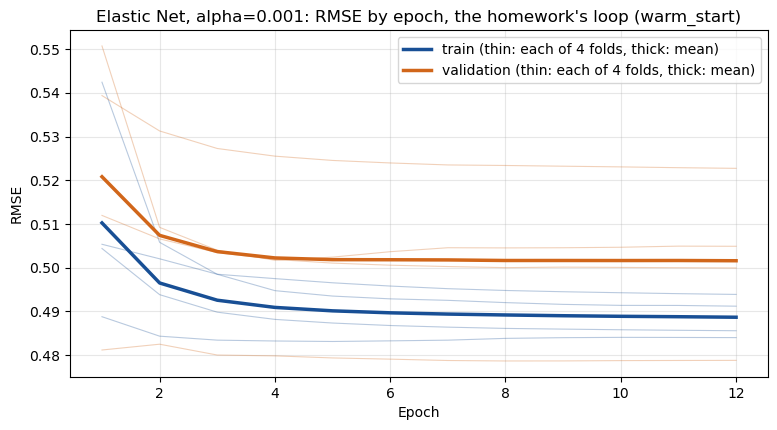

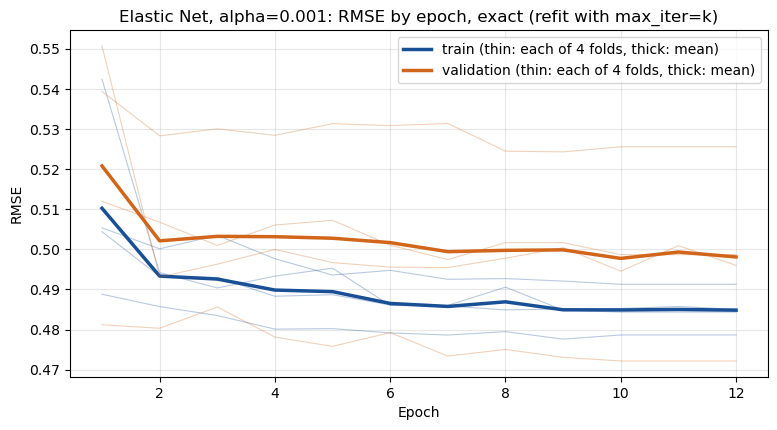

In [16]:
EPOCHS = int(RUNS[SELECTED]['epochs'].max())  # as many epochs as the selected model ran on its longest fold
pipeline = build(model=SGDRegressor(**SETTINGS[SELECTED]), imputer=IMPUTER, degree=DEGREE)
CURVES = {
	method: PIPELINES.epoch_rmse(pipeline=pipeline, X=X, y=y, folds=CV_FOLDS, epochs=EPOCHS, method=method)
	for method in ('warm_start', 'refit')
}
for method, label in (('warm_start', "the homework's loop (warm_start)"), ('refit', 'exact (refit with max_iter=k)')):
	PLOTTING.loss_curve(curve=CURVES[method], title=f'{SELECTED}: RMSE by epoch, {label}', ymax=YMAX);

### Notes / Observations

- **Most of the learning happens in the first 2 epochs:** on the exact curve validation RMSE drops from about 0.521 to about 0.502, then edges down to 0.4981.
- **More epochs do not overfit:** validation RMSE keeps edging down with training RMSE and never turns up.

### The Two Curves Side by Side

The mean of the folds for both curves on one chart, and the scores each ends on. The exact curve's last epoch is each fold's full fit, so it ends on the selected model's cross validation score from the Selected Model table; the homework's loop does not.

,validation rmse,train rmse
cross validation (Selected Model),0.4981,0.4848
"homework's loop, last epoch",0.5016,0.4887
"exact curve, last epoch",0.4981,0.4848


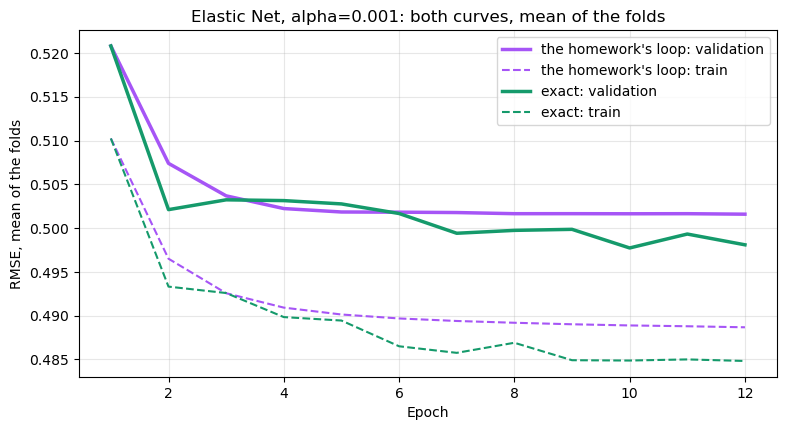

In [17]:
PLOTTING.loss_curve_comparison(curves=CURVES, title=f'{SELECTED}: both curves, mean of the folds', ymax=YMAX);
pd.DataFrame({
	'cross validation (Selected Model)': RUNS[SELECTED][['validation rmse', 'train rmse']].mean(),
	"homework's loop, last epoch": CURVES['warm_start'].xs(EPOCHS, level='epoch').mean(),
	'exact curve, last epoch': CURVES['refit'].xs(EPOCHS, level='epoch').mean(),
}).T[['validation rmse', 'train rmse']]

### Notes / Observations

- **The two curves start together and part at epoch 2:** epoch 1 is the same single pass in both. From epoch 2 the loop restarts `invscaling`'s step at 0.01 every epoch, while the long fit's step keeps shrinking.
- **The loop flattens early and ends higher:** its validation RMSE stops improving around epoch 5 and ends at 0.5016, against 0.4981 for the exact curve. Every epoch starts again with the large step, so the loop gets no closer to the best fit than one epoch can take it.
- **The loop's lines are smooth and the exact curve's are jagged:** the loop visits the rows in the same order every epoch, so each epoch repeats the same moves; the long fit reshuffles every epoch.
- **Only the exact curve ends on the cross validation score (0.4981),** so it is the one that shows how the selected model trained.

# Overfitting and Underfitting

Validation loss is read three ways in this notebook: by degree (Degree, closed form), by penalty (Regularization: a penalty that raises training RMSE without lowering validation RMSE has no overfitting to cure), and by epoch (the selected model's loss curve). Underfitting: training and validation RMSE both high and close; overfitting: training RMSE still falling while validation RMSE rises.

### Notes / Observations

- **By degree:** degree 1 underfits, degree 2 fits best, and from degree 3 the closed form overfits (training RMSE falls to 0.4083 while validation RMSE rises to 0.5942).
- **By penalty:** no penalty lowers validation RMSE by more than 0.0006, and the larger ones raise training and validation RMSE together, so there is no overfitting for a penalty to cure.
- **By epoch:** the selected model's validation RMSE falls and then holds, so more epochs do not overfit.
- **The selected degree 2 model fits well:** its gap between training and validation RMSE is small (0.4848 against 0.4981).